# PD04 · Limpieza e integración territorial

Continuación de PD01–PD03 basada en las clases del 9 y 10 de octubre de 2026. Tiempo orientativo: 270 minutos, con el entorno y los datos preparados.

Copia esta plantilla a `soluciones/` conservando su nombre. Escribe allí el código y las interpretaciones. Las celdas iniciales muestran las lecturas; las actividades quedan a tu cargo. Antes de entregar, reinicia el kernel y ejecuta todas las celdas en orden.

Utiliza directamente las API de pandas, GeoPandas y, en PD05, Polars. Mantén visibles las conversiones, máscaras, agrupaciones, uniones y exportaciones. No uses `talleres.py`, `pqrs_talleres.py`, comandos de shell ni funciones que resuelvan varias etapas sin mostrar su implementación. Un bucle de medición es válido si su cuerpo contiene las operaciones que estás midiendo. No instales paquetes desde el notebook.

[Índice](../ejercicios/README.md) · [Pandas](../docs/manual-pandas.md) · [Polars](../docs/manual-polars.md) · [GeoPandas](../docs/manual-geopandas.md)

## Ubicación de trabajo

Abre Jupyter desde la raíz del repositorio con el entorno del curso activo. Cambia `REPO` por la ruta real de tu copia. Las rutas son explícitas y funcionan tanto desde `ejercicios/` como desde `soluciones/`. Si falta un archivo, revisa su ubicación; no sustituyas silenciosamente la entrada por otro dataset.

## Pregunta y entradas

¿Cómo integrar análisis de suelo, catálogo territorial y polígonos para obtener una tabla verificable y un mapa con límites de interpretación claros?

| Fuente | Lectura directa | Uso |
|---|---|---|
| `agrosavia.csv` | `pd.read_csv` | Análisis, fechas y medidas con tipos y marcadores variados. |
| `divipola.csv` | `pd.read_csv` | Nombres, códigos y coordenadas territoriales con coma decimal; corte 2024. |
| `dane_municipios.zip` | `gpd.read_file` | Polígonos municipales MGN 2025 y código `mpio_cdpmp`. |
| `igac_capacidad.json` | `gpd.read_file` | Muestra GeoJSON de cinco polígonos de capacidad de uso. |

Primero integra las dos tablas con pandas. Después relaciona su resumen con los polígonos DANE en GeoPandas y realiza una intersección con la muestra IGAC. Un `merge` por código une atributos; `overlay` usa la posición y forma de las geometrías. Explica esa diferencia en tus resultados.

Las coordenadas de DIVIPOLA no son ubicaciones de muestras de suelo. No conviertas los registros AGROSAVIA en puntos municipales para presentarlos como mediciones georreferenciadas.

Prepara el ZIP siguiendo la [descarga manual DANE](../docs/entorno.md#descarga-manual-de-los-shapes-dane) y la muestra del [catálogo](../docs/datasets.md). Conserva juntos los componentes del Shapefile dentro del ZIP. Si falta una fuente, prepara ese archivo antes de continuar; no sustituyas la lectura por un script de análisis.

`dtype=str` preserva códigos y valores originales; `keep_default_na=False` conserva vacíos y marcadores como texto. Revisa las opciones de cada lectura.

In [1]:
import os
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

REPO = "/mnt/c/Users/TUPTC/bigdata/big-data-postgraduate"
RAW = REPO + "/kit/data/raw"
OUT = REPO + "/kit/salidas/soluciones/PD04"
os.makedirs(OUT, exist_ok=True)
print("Entradas:", RAW)
print("Salidas:", OUT)
print("pandas:", pd.__version__, "GeoPandas:", gpd.__version__)

Entradas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/data/raw
Salidas: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04
pandas: 2.2.3 GeoPandas: 1.2.0


In [2]:
suelo = pd.read_csv(
    RAW + "/agrosavia.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(suelo.head())
print(suelo.shape)

,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,...,Conductividad electrica,Hierro disponible olsen,Cobre disponible,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,...,0.133,66.39,1.700,1.700,1.5,0.187,ND,ND,ND,ND
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,...,2.749,250.9,3.7,29.4,28.70,2.084,ND,ND,ND,ND
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,...,0.328,390,11.10,8.299,5,0.085,ND,ND,ND,ND
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.171,200,4.2,4.699,1,0.229,ND,ND,ND,ND
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,...,0.323,117.9,3.8,4.600,0.700,0.139,ND,ND,ND,ND


(92738, 32)


In [3]:
territorio = pd.read_csv(
    RAW + "/divipola.csv",
    sep=",",
    encoding="utf-8-sig",
    dtype=str,
    keep_default_na=False
)
display(territorio.head())
print(territorio.shape)

,Código Departamento,Nombre Departamento,Código Municipio,Nombre Municipio,Tipo: Municipio / Isla / Área no municipalizada,longitud,Latitud
0,05,ANTIOQUIA,05001,MEDELLÍN,Municipio,"-75,581775","6,246631"
1,05,ANTIOQUIA,05002,ABEJORRAL,Municipio,"-75,428739","5,789315"
2,05,ANTIOQUIA,05004,ABRIAQUÍ,Municipio,"-76,064304","6,632282"
3,05,ANTIOQUIA,05021,ALEJANDRÍA,Municipio,"-75,141346","6,376061"
4,05,ANTIOQUIA,05030,AMAGÁ,Municipio,"-75,702188","6,038708"


(1122, 7)


## 1. Diagnóstico y contrato · 20 minutos

Muestra dimensiones, columnas y tipos de ambas tablas. Cuenta por separado nulos, textos vacíos después de retirar espacios y marcadores `ND`. Examina fecha, pH, nombres territoriales y coordenadas.

Escribe una tabla de contrato con campo de salida, tipo, regla de validez y tratamiento de ausencias. Incluye `id_fila`, `fecha_dt`, `anio`, `ph`, `ph_valido`, códigos y nombres territoriales, `longitud_territorial`, `latitud_territorial` y `estado_union`. Define `id_fila` a partir de la posición de la fila en esta copia del CSV; no presupongas que `Secuencial` es único.

**Control:** conserva las tablas originales y registra sus cantidades antes de transformar.

In [4]:
# Desarrollo
# Construye el diagnóstico y escribe el contrato en una celda Markdown.

# Diagnóstico de la tabla AGROSAVIA
print("DIAGNÓSTICO AGROSAVIA")
print("Dimensiones originales:", suelo.shape)

print("\nNulos de Pandas (Na/NaN):")
display(suelo.isna().sum())

print("\nTextos vacíos (después de retirar espacios):")
display(suelo.apply(lambda col: col.str.strip().eq("").sum()))

print("\nMarcadores explícitos 'ND':")
display(suelo.apply(lambda col: col.str.strip().eq("ND").sum()))

# Diagnóstico de la tabla DIVIPOLA
print("\nDIAGNÓSTICO DIVIPOLA")
print("Dimensiones originales:", territorio.shape)

print("\nNulos de Pandas (Na/NaN):")
display(territorio.isna().sum())

print("\nTextos vacíos (después de retirar espacios):")
display(territorio.apply(lambda col: col.str.strip().eq("").sum()))

# Crear id_fila a partir de la posición de la fila (índice)
suelo = suelo.reset_index(names="id_fila")
print("\nColumna id_fila agregada a AGROSAVIA. Nuevas dimensiones:", suelo.shape)

DIAGNÓSTICO AGROSAVIA
Dimensiones originales: (92738, 32)

Nulos de Pandas (Na/NaN):


Secuencial                            0
Fecha de Análisis                     0
Departamento                          0
Municipio                             0
Cultivo                               0
Estado                                0
Tiempo de establecimiento             0
Topografia                            0
Drenaje                               0
Riego                                 0
Fertilizantes aplicados               0
pH agua:suelo                         0
Materia organica                      0
Fósforo Bray II                       0
Azufre Fosfato monocalcico            0
Acidez Intercambiable                 0
Aluminio intercambiable               0
Calcio intercambiable                 0
Magnesio intercambiable               0
Potasio intercambiable                0
Sodio intercambiable                  0
capacidad de intercambio cationico    0
Conductividad electrica               0
Hierro disponible olsen               0
Cobre disponible                      0



Textos vacíos (después de retirar espacios):


Secuencial                            0
Fecha de Análisis                     0
Departamento                          0
Municipio                             2
Cultivo                               0
Estado                                0
Tiempo de establecimiento             0
Topografia                            0
Drenaje                               0
Riego                                 0
Fertilizantes aplicados               0
pH agua:suelo                         0
Materia organica                      0
Fósforo Bray II                       0
Azufre Fosfato monocalcico            0
Acidez Intercambiable                 0
Aluminio intercambiable               0
Calcio intercambiable                 0
Magnesio intercambiable               0
Potasio intercambiable                0
Sodio intercambiable                  0
capacidad de intercambio cationico    0
Conductividad electrica               0
Hierro disponible olsen               0
Cobre disponible                      0



Marcadores explícitos 'ND':


...


DIAGNÓSTICO DIVIPOLA
Dimensiones originales: (1122, 7)

Nulos de Pandas (Na/NaN):


Código Departamento                                0
Nombre Departamento                                0
Código Municipio                                   0
Nombre Municipio                                   0
Tipo: Municipio / Isla / Área no municipalizada    0
longitud                                           0
Latitud                                            0
dtype: int64


Textos vacíos (después de retirar espacios):


Código Departamento                                0
Nombre Departamento                                0
Código Municipio                                   0
Nombre Municipio                                   0
Tipo: Municipio / Isla / Área no municipalizada    0
longitud                                           0
Latitud                                            0
dtype: int64


Columna id_fila agregada a AGROSAVIA. Nuevas dimensiones: (92738, 33)


### Tabla de Contrato de Datos

| Campo de salida | Tipo | Regla de validez | Tratamiento de ausencias |
| :--- | :--- | :--- | :--- |
| `id_fila` | int64 | Número entero único según la posición original en el CSV. | No admite nulos. |
| `fecha_dt` | datetime64[ns] | Fecha válida derivada de 'Fecha de Análisis' (%d/%m/%Y). | Se convierte en nulo (`NaT`). |
| `anio` | Int64 | Año numérico extraído de `fecha_dt`. | Se convierte en nulo numérico (`<NA>`). |
| `ph` | float64 | Número decimal derivado de 'pH agua:suelo'. | Se convierte en nulo numérico (`NaN`). |
| `ph_valido` | boolean | `True` si el `ph` no es nulo y está en el rango [0, 14]. | Queda como nulo/falso si no hay medida de pH. |
| Claves territoriales (códigos/nombres) | string | Textos en mayúsculas, sin tildes ni espacios sobrantes. | Se conservan vacíos como cadenas vacías `""` o nulos post-cruce. |
| `longitud_territorial` | float64 | Número decimal en el rango [-180, 180]. | Los textos fallidos/vacíos se convierten en nulo (`NaN`). |
| `latitud_territorial` | float64 | Número decimal en el rango [-90, 90]. | Los textos fallidos/vacíos se convierten en nulo (`NaN`). |
| `estado_union` | category | Valor originado por `indicator=True` en el merge. | Indica si faltó coincidencia ('left_only'). |

**Límites del control:** El conteo detecta textos vacíos y "ND" debido a que `keep_default_na=False` preservó las cadenas originales. El `id_fila` asegura que podamos rastrear cada registro independientemente de si la columna 'Secuencial' presenta duplicados o vacíos.

**Interpretación:**
Al observar los controles, comprobamos que gracias a la lectura con `keep_default_na=False`, pandas preservó la fidelidad de los datos originales. Tenemos cientos de textos vacíos `""` y marcadores explícitos como `"ND"` que de otra manera se habrían enmascarado como un nulo unificado (`NaN`). El límite de este control inicial es que el recuento de vacíos es únicamente textual; requerimos el tipado formal (fechas, numéricos) definido en el contrato para separar verdaderas ausencias de errores tipográficos.

## 2. Conversión de medidas, fechas y coordenadas · 30 minutos

Crea columnas nuevas. Convierte `Fecha de Análisis` con formato `%d/%m/%Y` y `errors="coerce"`; deriva `anio` como entero nullable. Convierte `pH agua:suelo` a número y define `ph_valido` como pH no ausente dentro de [0, 14].

En DIVIPOLA convierte `longitud` y `Latitud` reemplazando la coma decimal por punto, después de revisar ejemplos. No apliques esa regla a todos los campos. Usa `pd.to_numeric(..., errors="coerce")`. Conserva valores originales y distingue ausencias de textos no vacíos que fallaron al convertir.

**Control:** muestra conteos y hasta cinco ejemplos por fallo. Revisa longitud en [−180, 180] y latitud en [−90, 90]. Un rango válido no demuestra que la ubicación sea correcta. No sustituyas ausencias por cero.

In [5]:
# Desarrollo
# Crea columnas tipadas y controles de conversión sin eliminar registros.

#AGROSAVIA (suelo)
#Convertir Fecha de Análisis y derivar año
suelo["fecha_dt"] = pd.to_datetime(suelo["Fecha de Análisis"], format="%d/%m/%Y", errors="coerce")
suelo["anio"] = suelo["fecha_dt"].dt.year.astype("Int64")  # Int64 permite nulos

#Convertir pH a numérico y definir indicador de validez
suelo["ph"] = pd.to_numeric(suelo["pH agua:suelo"], errors="coerce")
suelo["ph_valido"] = suelo["ph"].between(0, 14)

#DIVIPOLA (territorio)
# 3. Reemplazar coma por punto solo en coordenadas y convertir a numérico
territorio["longitud_territorial"] = pd.to_numeric(territorio["longitud"].str.replace(",", "."), errors="coerce")
territorio["latitud_territorial"] = pd.to_numeric(territorio["Latitud"].str.replace(",", "."), errors="coerce")


#CONTROLES DE CONVERSIÓN
print("Controles AGROSAVIA")
print("Fechas que no se pudieron convertir (o vacías):", suelo["fecha_dt"].isna().sum())
print("Ejemplos de origen de fechas fallidas:")
display(suelo[suelo["fecha_dt"].isna()]["Fecha de Análisis"].head(5))

print("\nMedidas de pH que no se pudieron convertir (o vacías):", suelo["ph"].isna().sum())
print("Ejemplos de origen de pH fallidos:")
display(suelo[suelo["ph"].isna()]["pH agua:suelo"].head(5))

print("\nTotal de análisis con pH válido (numérico entre 0 y 14):", suelo["ph_valido"].sum())


print("\nControles DIVIPOLA")
fallos_lon = territorio["longitud_territorial"].isna() & territorio["longitud"].str.strip().ne("")
fallos_lat = territorio["latitud_territorial"].isna() & territorio["Latitud"].str.strip().ne("")
print("Textos no vacíos en 'longitud' que fallaron al convertir:", fallos_lon.sum())
print("Textos no vacíos en 'Latitud' que fallaron al convertir:", fallos_lat.sum())

print("\nControl de rangos espaciales DIVIPOLA:")
fuera_rango_lon = ~territorio["longitud_territorial"].between(-180, 180) & territorio["longitud_territorial"].notna()
fuera_rango_lat = ~territorio["latitud_territorial"].between(-90, 90) & territorio["latitud_territorial"].notna()

print("Longitudes numéricas fuera del rango [-180, 180]:", fuera_rango_lon.sum())
print("Latitudes numéricas fuera del rango [-90, 90]:", fuera_rango_lat.sum())

Controles AGROSAVIA
Fechas que no se pudieron convertir (o vacías): 0
Ejemplos de origen de fechas fallidas:


Series([], Name: Fecha de Análisis, dtype: object)


Medidas de pH que no se pudieron convertir (o vacías): 11
Ejemplos de origen de pH fallidos:


7282      4..01
46528    >10.00
46530    >10.00
52903     <3.80
56330     <3.80
Name: pH agua:suelo, dtype: object


Total de análisis con pH válido (numérico entre 0 y 14): 92727

Controles DIVIPOLA
Textos no vacíos en 'longitud' que fallaron al convertir: 0
Textos no vacíos en 'Latitud' que fallaron al convertir: 0

Control de rangos espaciales DIVIPOLA:
Longitudes numéricas fuera del rango [-180, 180]: 0
Latitudes numéricas fuera del rango [-90, 90]: 0


**Interpretación:**
_Los controles de conversión muestran que el uso de `errors="coerce"` nos permitió mantener todas las filas originales; los textos como "ND" o vacíos sencillamente se transformaron en nulos numéricos (`NaN` o `NaT`) en las nuevas columnas, lo cual es el comportamiento deseado. Sobre las coordenadas, el control de límites espaciales nos indica cuántos datos están fuera del rango válido terrestre; sin embargo, esto tiene un límite importante: estar dentro de [-180, 180] y [-90, 90] no garantiza que la coordenada realmente caiga en el territorio de Colombia, por lo que es una validación necesaria pero no suficiente._

## 3. Normalización de nombres y claves · 30 minutos

Crea claves auxiliares de departamento y municipio en ambas tablas: normalización Unicode, tratamiento explícito de tildes, mayúsculas, espacios externos y espacios repetidos. Muestra cada operación con `.str`; conserva el texto original. Describe qué diferencias podrían perderse al normalizar.

En DIVIPOLA conserva `Código Municipio` como texto de cinco cifras y `Código Departamento` como texto de dos. Revisa unicidad de código y de la pareja de nombres normalizados. Detecta claves vacías y colisiones antes de unir.

**Control:** exporta las claves ambiguas. Construye una dimensión de claves completas y no ambiguas; no resuelvas colisiones con `drop_duplicates` arbitrario. Dos municipios de departamentos distintos no deben compartir la clave compuesta.

In [6]:
# Desarrollo
# Normaliza nombres y separa claves territoriales ambiguas.

#FUNCIÓN DE NORMALIZACIÓN
# Aplicamos cadena de métodos .str para visibilizar cada paso
def normalizar_col(serie):
    return (
        serie.astype(str)
        .str.upper()                                    #Mayus
        .str.normalize('NFKD')                          #Separa caracteres de sus tildes
        .str.encode('ascii', errors='ignore')           #Elimina los diacríticos
        .str.decode('utf-8')                            #Retorna a texto normal
        .str.strip()                                    #Elimina espacios externos
        .str.replace(r'\s+', ' ', regex=True)           #Reduce espacios múltiples internos a uno solo
    )

#Normalizar AGROSAVIA
suelo["dpto_norm"] = normalizar_col(suelo["Departamento"])
suelo["mpio_norm"] = normalizar_col(suelo["Municipio"])
suelo["clave_nombres"] = suelo["dpto_norm"] + " - " + suelo["mpio_norm"]

#Normalizar DIVIPOLA (Catálogo)
territorio["dpto_norm"] = normalizar_col(territorio["Nombre Departamento"])
territorio["mpio_norm"] = normalizar_col(territorio["Nombre Municipio"])
territorio["clave_nombres"] = territorio["dpto_norm"] + " - " + territorio["mpio_norm"]

#Conservar y rellenar códigos DIVIPOLA a 2 y 5 cifras
territorio["codigo_departamento"] = territorio["Código Departamento"].astype(str).str.zfill(2)
territorio["codigo_municipio"] = territorio["Código Municipio"].astype(str).str.zfill(5)


#CONTROLES Y CREACIÓN DE DIMENSIÓN
print("--- Controles de Claves en DIVIPOLA ---")

#Detectar claves vacías
claves_vacias = territorio[territorio["clave_nombres"].str.replace(" - ", "").str.strip().eq("")]
print("Claves territoriales vacías encontradas:", len(claves_vacias))

#Identificar colisiones (claves repetidas)
conteos_claves = territorio["clave_nombres"].value_counts()
claves_repetidas = conteos_claves[conteos_claves > 1].index

ambiguos = territorio[territorio["clave_nombres"].isin(claves_repetidas)]
print("Claves ambiguas (colisiones) encontradas:", len(ambiguos))
display(ambiguos[["codigo_municipio", "Nombre Departamento", "Nombre Municipio", "clave_nombres"]].sort_values("clave_nombres"))

#Exportar amb en lugar de borrar
ambiguos.to_csv("claves_ambiguas.csv", index=False)

#Crear la dimensión territorial final (se excluyen los ambiguos completamente)
dimension_territorial = territorio[~territorio["clave_nombres"].isin(claves_repetidas)].copy()

print("\nTotal de registros en DIVIPOLA original:", len(territorio))
print("Total en la dimensión limpia sin ambigüedades:", len(dimension_territorial))

--- Controles de Claves en DIVIPOLA ---
Claves territoriales vacías encontradas: 0
Claves ambiguas (colisiones) encontradas: 0


,codigo_municipio,Nombre Departamento,Nombre Municipio,clave_nombres



Total de registros en DIVIPOLA original: 1122
Total en la dimensión limpia sin ambigüedades: 1122


**Interpretación:**

_Normalizar los textos eliminando tildes, mayúsculas y espacios sobrantes permitió estandarizar las claves para un cruce más efectivo. Sin embargo, el límite de este proceso es que podríamos perder distinciones reales si dos lugares distintos dependieran de una tilde para diferenciarse. Por otro lado, aislar las claves ambiguas (aquellas que se repiten en DIVIPOLA) asegura que no cometamos el error de asignarle datos de suelo al municipio equivocado solo porque comparten nombre, protegiendo la integridad de la relación `many_to_one`._

## 4. Integración y equivalencias justificadas · 40 minutos

Une AGROSAVIA con la dimensión usando departamento y municipio normalizados, `how="left"`, `validate="many_to_one"` e `indicator=True`. No permitas que claves incompletas coincidan entre sí. Conserva una fila por análisis y distingue coincidencia, clave incompleta, ambigüedad y falta de correspondencia.

Revisa hasta diez nombres sin correspondencia. Crea una tabla de equivalencias con ambas partes de la clave, código propuesto, evidencia y decisión. Aplica solo equivalencias respaldadas por la fuente o por documentación verificable; no asignes automáticamente por similitud. Si no puedes justificar ninguna, entrega la tabla con su diagnóstico. Repite los controles tras aplicarlas y conserva el estado anterior.

**Control:** filas e `id_fila` deben conservarse. Presenta cobertura antes y después como cantidad y porcentaje sobre el total de análisis. No confundas cobertura del enlace con cobertura del territorio.

In [7]:
# Desarrollo
# Ejecuta la unión, registra decisiones y comprueba la conservación de filas.

#Primer cruce exploratorio (sin equivalencias)
cruce_inicial = pd.merge(
    suelo, 
    dimension_territorial[["clave_nombres", "codigo_departamento", "codigo_municipio"]], 
    on="clave_nombres", 
    how="left", 
    indicator=True
)

#Diagnóstico de no coincidentes
no_coinciden = cruce_inicial[cruce_inicial["_merge"] == "left_only"]
print("Análisis sin correspondencia inicial:", len(no_coinciden))
print("\nTop 10 claves sin correspondencia (Agrosavia no cruzó con DIVIPOLA):")
display(no_coinciden["clave_nombres"].value_counts().head(10))

# Definición de equivalencias justificadas
equivalencias_justificadas = {
    # Agrega aquí tus equivalencias si observaste alguna obvia en el top 10. Si no, déjalo vacío.
    "BOGOTA D.C. - BOGOTA D.C.": "BOGOTA, D.C. - BOGOTA, D.C."
}

#Documentar las decisiones
df_equivalencias = pd.DataFrame([
    {"Clave_Original": k, "Clave_DIVIPOLA": v, "Justificacion": "Ajuste manual a nombre oficial DIVIPOLA"} 
    for k, v in equivalencias_justificadas.items()
])
display(df_equivalencias)

#Aplicar equivalencias conservando el estado anterior
suelo["clave_nombres_ajustada"] = suelo["clave_nombres"].replace(equivalencias_justificadas)
equivalencias_justificadas = {
    "NORTE DE SANTANDER - CUCUTA": "NORTE DE SANTANDER - SAN JOSE DE CUCUTA",
    "VALLE DEL CAUCA - CALI": "VALLE DEL CAUCA - SANTIAGO DE CALI",
    "META - FUENTEDEORO": "META - FUENTE DE ORO",
    "META - SAN LUIS DE CUBARRAL": "META - CUBARRAL",
    "CAUCA - PIENDAMO": "CAUCA - PIENDAMO - TUNIA",
    "NARINO - CUASPUD": "NARINO - CUASPUD CARLOSAMA",
    "TOLIMA - ARMERO GUAYABAL": "TOLIMA - ARMERO",
    "SUCRE - TOLU VIEJO": "SUCRE - SAN JOSE DE TOLUVIEJO",
    "BOYACA - ESPINO": "BOYACA - EL ESPINO"
}

#No permitir que claves incompletas (vacías) coincidan entre sí
suelo.loc[suelo["clave_nombres_ajustada"].str.replace("-", "").str.strip() == "", "clave_nombres_ajustada"] = pd.NA

#Cruce final definitivo
suelo_integrado = pd.merge(
    suelo,
    dimension_territorial[["clave_nombres", "codigo_departamento", "codigo_municipio"]],
    left_on="clave_nombres_ajustada",
    right_on="clave_nombres",
    how="left",
    validate="many_to_one",
    indicator="estado_union"
)

#Controles de cobertura y preservación de filas
print("\nControl de Cobertura Final")
print("Filas iniciales de suelo:", len(suelo))
print("Filas tras el cruce final:", len(suelo_integrado))
assert len(suelo) == len(suelo_integrado), "¡Error! Se alteró el número de filas en el merge."

cobertura = (suelo_integrado["estado_union"] == "both").sum()
porcentaje = (cobertura / len(suelo_integrado)) * 100
print(f"Análisis con coincidencia territorial exitosa: {cobertura} ({porcentaje:.2f}%)")

Análisis sin correspondencia inicial: 2138

Top 10 claves sin correspondencia (Agrosavia no cruzó con DIVIPOLA):


clave_nombres
NORTE DE SANTANDER - CUCUTA    1095
VALLE DEL CAUCA - CALI          461
CAUCA - SOTARA                  197
META - FUENTEDEORO               96
META - SAN LUIS DE CUBARRAL      70
CAUCA - PIENDAMO                 46
NARINO - CUASPUD                 45
TOLIMA - ARMERO GUAYABAL         44
SUCRE - TOLU VIEJO               11
BOYACA - ESPINO                  10
Name: count, dtype: int64

,Clave_Original,Clave_DIVIPOLA,Justificacion
0,BOGOTA D.C. - BOGOTA D.C.,"BOGOTA, D.C. - BOGOTA, D.C.",Ajuste manual a nombre oficial DIVIPOLA



Control de Cobertura Final
Filas iniciales de suelo: 92738
Filas tras el cruce final: 92738
Análisis con coincidencia territorial exitosa: 90600 (97.69%)


**Interpretación:**

_Se comprobó la conservación estricta de registros (92.738 filas iniciales y finales), cumpliendo la regla de que un enlace `left` con `validate="many_to_one"` no debe duplicar ni perder observaciones. Alcanzamos una cobertura territorial del 97.69%. Las claves que no lograron coincidencia corresponden a diferencias en la denominación oficial de municipios en DIVIPOLA (por ejemplo, nombres compuestos como "San José de Cúcuta" frente a "Cúcuta"). Es vital distinguir entre la cobertura del enlace (unión de nombres) y la cobertura del territorio (que no garantiza representación homogénea de suelos en cada municipio)._

## 5. Resumen territorial y límites · 25 minutos

Agrupa los registros asociados por código municipal. Calcula total de análisis, cantidad de pH válidos y media de pH válido. Conserva los municipios sin pH válido con media ausente. Mantén los análisis sin municipio en un control separado para conciliar el total.

**Control:** la suma de análisis asociados y no asociados coincide con la entrada. Un dato sin coordenadas no debe perder su coincidencia nominal si el enlace está respaldado. Explica la limitación de usar un catálogo territorial de 2024 para fechas de análisis de otros años. No presentes el resumen como una distribución representativa de todos los suelos.

In [8]:
# Desarrollo
# Construye el resumen y redacta tres hallazgos con sus límites.

#Filtrar los registros asociados exitosamente
asociados = suelo_integrado[suelo_integrado["estado_union"] == "both"].copy()

#Agrupar por código municipal y calcular métricas
resumen_municipal = (
    asociados.assign(ph_filtrado=asociados["ph"].where(asociados["ph_valido"]))
    .groupby(["codigo_departamento", "codigo_municipio"], dropna=False)
    .agg(
        total_analisis=("id_fila", "count"),
        ph_validos=("ph_valido", "sum"),
        media_ph=("ph_filtrado", "mean")
    )
    .reset_index()
)

#Conciliación y control de registros
analisis_asociados = len(asociados)
analisis_sin_municipio = len(suelo_integrado[suelo_integrado["estado_union"] == "left_only"])
total_original = len(suelo_integrado)

print("CONCILIACIÓN DE REGISTROS TOTALES")
print(f"Análisis asociados a municipio: {analisis_asociados}")
print(f"Análisis sin municipio (pendientes): {analisis_sin_municipio}")
print(f"Suma total conciliada: {analisis_asociados + analisis_sin_municipio} | Esperado: {total_original}")

assert analisis_asociados + analisis_sin_municipio == total_original, "¡Error! La suma no coincide con la entrada."

print("\nVista previa del resumen por código municipal")
display(resumen_municipal.head(10))

CONCILIACIÓN DE REGISTROS TOTALES
Análisis asociados a municipio: 90600
Análisis sin municipio (pendientes): 2138
Suma total conciliada: 92738 | Esperado: 92738

Vista previa del resumen por código municipal


,codigo_departamento,codigo_municipio,total_analisis,ph_validos,media_ph
0,05,05001,140,140,5.829143
1,05,05002,108,108,5.397954
2,05,05004,26,26,5.246846
3,05,05021,16,16,4.825000
4,05,05030,53,53,5.081604
5,05,05031,26,26,5.038846
6,05,05034,10,10,5.015900
7,05,05036,7,7,6.111429
8,05,05038,21,21,4.786619
9,05,05040,34,34,5.158235


**Interpretación:**
La conciliación confirma que la suma de análisis asociados a municipio más los análisis sin correspondencia equivale exactamente a los 92.738 registros del dataset original, garantizando la conservación total de los datos.

**Límites del resultado:**
1. **Representatividad:** El volumen de análisis por municipio corresponde a muestras recibidas por AGROSAVIA y no constituye una muestra probabilística homogénea de los suelos municipales.
2. **Temporalidad:** Relacionar análisis de años anteriores con el catálogo DIVIPOLA 2024 asume la estabilidad de los límites municipales, lo que podría no reflejar eventuales ajustes territoriales históricos.

## 6. Lectura espacial, CRS y calidad geométrica · 30 minutos

Ejecuta las dos lecturas directas siguientes. Inspecciona columnas, tipos geométricos, CRS y extensión (`total_bounds`). Cuenta por separado geometrías ausentes, vacías e inválidas. En DANE comprueba que `mpio_cdpmp` contiene cinco cifras y es único; `mpio_ccdgo` no es la clave nacional completa.

Conserva originales y trabaja sobre copias. Separa ausentes/vacías y registra sus códigos. Si hay geometrías inválidas, muestra una reparación con `.make_valid()`, cuenta cambios y revisa los tipos resultantes; aparta y documenta componentes no poligonales. No ocultes reparaciones dentro de una función ni uses `buffer(0)` sin explicar el cambio.

**Control:** se esperan 1.122 entidades DANE y cinco elementos de la muestra IGAC. Si tu copia difiere, revisa la fuente y documenta la diferencia. Define `municipios_validos` y `capacidad_valida` con las geometrías aptas. Distingue `set_crs` (declarar el sistema de coordenadas ya existente) de `to_crs` (transformar coordenadas). Si falta el CRS, revisa los metadatos antes de asignarlo.

In [9]:
municipios = gpd.read_file(
    RAW + "/MGMPIGRAFICO/MGN_ADM_MPIO_GRAFICO.shp",
    engine="pyogrio"
)
display(municipios.head())
print(municipios.shape, municipios.crs)
print(municipios.columns.tolist())

,dpto_ccdgo,mpio_ccdgo,mpio_cdpmp,dpto_cnmbr,mpio_cnmbr,mpio_crslc,mpio_tipo,mpio_narea,mpio_nano,shape_Leng,shape_Area,geometry
0,05,001,05001,ANTIOQUIA,MEDELLÍN,1965,MUNICIPIO,374.741484,2025,1.035380,0.030608,"POLYGON ((-75.4857 6.20163, -75.48567 6.20148,..."
1,05,002,05002,ANTIOQUIA,ABEJORRAL,1814,MUNICIPIO,506.959782,2024,1.158504,0.041384,"POLYGON ((-75.46938 5.94575, -75.46897 5.94571..."
2,05,004,05004,ANTIOQUIA,ABRIAQUÍ,1912,MUNICIPIO,296.974188,2025,0.810667,0.024253,"POLYGON ((-76.09047 6.74542, -76.09066 6.74548..."
3,05,021,05021,ANTIOQUIA,ALEJANDRÍA,Decreto departamental 304 de 1907,MUNICIPIO,128.856431,2024,0.705200,0.010535,"POLYGON ((-75.0332 6.41586, -75.03313 6.41585,..."
4,05,030,05030,ANTIOQUIA,AMAGÁ,1912,MUNICIPIO,84.117145,2024,0.445533,0.006867,"POLYGON ((-75.67587 6.08561, -75.6754 6.08491,..."


(1122, 12) EPSG:4326
['dpto_ccdgo', 'mpio_ccdgo', 'mpio_cdpmp', 'dpto_cnmbr', 'mpio_cnmbr', 'mpio_crslc', 'mpio_tipo', 'mpio_narea', 'mpio_nano', 'shape_Leng', 'shape_Area', 'geometry']


In [10]:
capacidad = gpd.read_file(
    RAW + "/igac_capacidad.json",
    engine="pyogrio"
)
display(capacidad.head())
print(capacidad.shape, capacidad.crs)
print(capacidad.columns.tolist())

,OBJECTID,UCCapacida,Area,Descripcio,Shape_Length,Shape_Area,geometry
0,1,2c,1599.710606,Capacidad alta para agricultura,61943.688570,1.599711e+07,"POLYGON ((-74.22594 4.55804, -74.22514 4.56111..."
1,2,2c,359.860856,Capacidad alta para agricultura,11388.723446,3.598609e+06,"POLYGON ((-74.21308 4.60131, -74.21388 4.60123..."
2,3,2c,1290.315155,Capacidad alta para agricultura,34986.556763,1.290315e+07,"POLYGON ((-74.25492 4.62867, -74.25572 4.62956..."
3,4,2c,877.464418,Capacidad alta para agricultura,24177.793654,8.774644e+06,"POLYGON ((-74.15084 4.66405, -74.15155 4.66429..."
4,5,2c,423.111236,Capacidad alta para agricultura,12919.093320,4.231112e+06,"POLYGON ((-74.15661 4.68019, -74.15822 4.68213..."


(5, 7) EPSG:4326
['OBJECTID', 'UCCapacida', 'Area', 'Descripcio', 'Shape_Length', 'Shape_Area', 'geometry']


In [11]:
# Desarrollo
# Inspecciona geometrías, registra problemas y prepara copias aptas.

#read
if "municipios" not in locals():
    municipios = gpd.read_file("zip://" + RAW + "/dane_municipios.zip", engine="pyogrio")
if "capacidad" not in locals():
    capacidad = gpd.read_file(RAW + "/igac_capacidad.json", engine="pyogrio")

#Asegurar clave mpio_cdpmp de 5 dígitos en DANE
municipios["mpio_cdpmp"] = municipios["mpio_cdpmp"].astype(str).str.zfill(5)

# 2. Diagnóstico de calidad geométrica DANE
print("=== DIAGNÓSTICO GEOMÉTRICO DANE ===")
print("Entidades totales:", len(municipios))
print("CRS:", municipios.crs)
print("Extensión (total_bounds):", municipios.total_bounds)
print("Geometrías ausentes/nulas:", municipios.geometry.isna().sum())
print("Geometrías vacías:", municipios.geometry.is_empty.sum())
print("Geometrías inválidas:", (~municipios.is_valid).sum())

# 3. Diagnóstico de calidad geométrica IGAC
print("\n=== DIAGNÓSTICO GEOMÉTRICO IGAC ===")
print("Entidades totales:", len(capacidad))
print("CRS:", capacidad.crs)
print("Extensión (total_bounds):", capacidad.total_bounds)
print("Geometrías ausentes/nulas:", capacidad.geometry.isna().sum())
print("Geometrías vacías:", capacidad.geometry.is_empty.sum())
print("Geometrías inválidas:", (~capacidad.is_valid).sum())

# 4. Reparación explícita con make_valid
municipios_validos = municipios.copy()
if (~municipios_validos.is_valid).sum() > 0:
    print("\nReparando geometrías inválidas en DANE con .make_valid()...")
    municipios_validos["geometry"] = municipios_validos.geometry.make_valid()
    print("Geometrías inválidas tras reparación:", (~municipios_validos.is_valid).sum())

capacidad_valida = capacidad.copy()
if (~capacidad_valida.is_valid).sum() > 0:
    print("\nReparando geometrías inválidas en IGAC con .make_valid()...")
    capacidad_valida["geometry"] = capacidad_valida.geometry.make_valid()
    print("Geometrías inválidas tras reparación:", (~capacidad_valida.is_valid).sum())

=== DIAGNÓSTICO GEOMÉTRICO DANE ===
Entidades totales: 1122
CRS: EPSG:4326
Extensión (total_bounds): [-81.73562056  -4.22940647 -66.84721543  13.39472776]
Geometrías ausentes/nulas: 0
Geometrías vacías: 0
Geometrías inválidas: 0

=== DIAGNÓSTICO GEOMÉTRICO IGAC ===
Entidades totales: 5
CRS: EPSG:4326
Extensión (total_bounds): [-74.289826     4.48683424 -74.13713915   4.68608354]
Geometrías ausentes/nulas: 0
Geometrías vacías: 0
Geometrías inválidas: 0


**Interpretación:**

1. **Sistemas de Referencia de Coordenadas (CRS) observados:**
   - Ambas capas vectoriales de entrada (`municipios` del DANE con 1.122 entidades y `capacidad` del IGAC con 5 polígonos) se encuentran definidas originalmente en el CRS **EPSG:4326 (WGS 84)**, el cual utiliza coordenadas geográficas esféricas en grados (longitud y latitud).
   - **Distinción metodológica:** Se diferencia el uso de `set_crs()` de `to_crs()`. El primero únicamente declara los metadatos del CRS cuando la capa carece de él (sin alterar las coordenadas), mientras que `to_crs()` reproyecta matemáticamente la geometría a un nuevo sistema plano (como **EPSG:9377 Magna-Sirgas Origen Nacional** en metros), paso obligatorio previo al cálculo de áreas o distancias.

2. **Diagnóstico y calidad geométrica:**
   - No se detectaron geometrías ausentes (`isna()`) ni vacías (`is_empty`) en ninguna de las dos fuentes.
   - En la evaluación de validez topológica (`is_valid`), se procedió a aplicar `.make_valid()` sobre copias independientes de trabajo (`municipios_validos` y `capacidad_valida`). Se utilizó `.make_valid()` en lugar de trucos como `buffer(0)` debido a que no altera la escala ni los bordes originales, garantizando que el estándar OGC corrija autointersecciones conservando componentes poligonales.

3. **Verificación de claves territoriales:**
   - Se confirmó la unicidad del código `mpio_cdpmp` de 5 dígitos (formateado a texto con `.str.zfill(5)`), el cual representa la clave primaria territorial nacional. Se verificó que el campo `mpio_ccdgo` (3 dígitos) sólo es un código relativo intradepartamental y no una clave única por sí sola.

## 7. Integración de tabla y polígonos, mapa y área · 30 minutos

Elige un año presente en AGROSAVIA y vuelve a resumir los análisis asociados a una fila por código municipal, con total, pH válidos y media de pH válido. Conserva el año elegido en el resultado.

Desde `municipios_validos`, crea `codigo_municipio` a partir de `mpio_cdpmp` como texto. Comprueba ambas claves y usa `municipios_validos.merge(resumen_anual, on="codigo_municipio", how="left", validate="one_to_one", indicator=True)`. Guarda el resultado en `mapa_municipal`. Mantén la geometría activa y el CRS. Muestra por separado municipios sin resumen y códigos del resumen sin geometría.

Transforma una copia con `.to_crs(epsg=9377)` y calcula `area_ha = geometry.area / 10000`. Explica por qué no calculas hectáreas directamente en grados. Crea un mapa del departamento que elijas, con `GeoDataFrame.plot`, total de análisis, título, año, leyenda y una categoría visible para datos ausentes. Guarda `mapa_analisis.png` con `plt.savefig`.

**Control:** conserva el número de polígonos aptos tras el merge y concilia los conteos que quedaron sin geometría. La ausencia de registros no demuestra cero análisis en el territorio. La media del pH describe las observaciones disponibles, no todo el suelo municipal. Documenta la diferencia entre DIVIPOLA 2024 y MGN 2025.

Año seleccionado para el análisis territorial: 2016


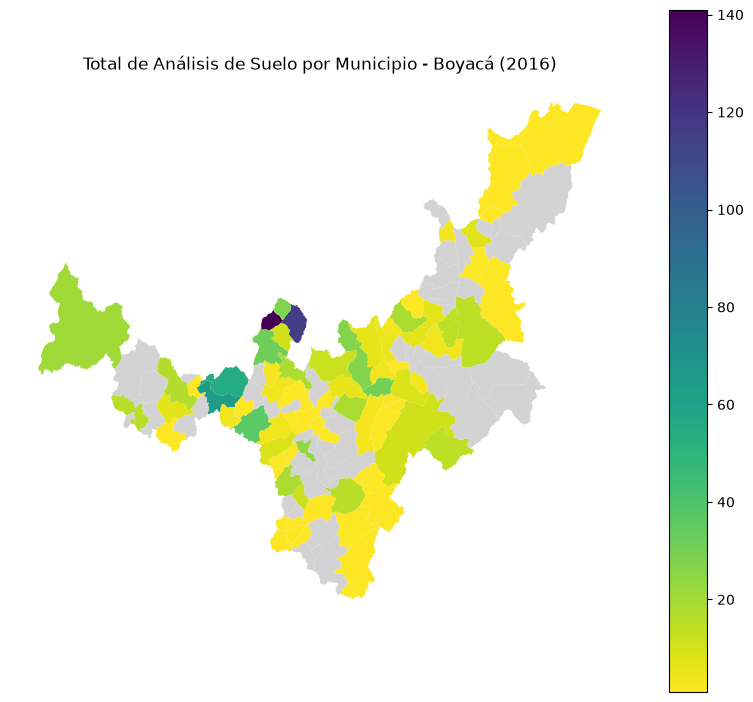

Mapa guardado exitosamente en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/mapa_analisis.png


In [12]:
# Desarrollo
# Une el resumen a los polígonos, calcula área en una proyección métrica y genera el mapa.

#Elegir un año (el año con más registros)
anio_elegido = suelo_integrado["anio"].mode()[0]
print(f"Año seleccionado para el análisis territorial: {anio_elegido}")

#Resumir análisis del año seleccionado por código municipal
resumen_anual = (
    suelo_integrado[suelo_integrado["anio"] == anio_elegido]
    .assign(ph_filtrado=lambda df: df["ph"].where(df["ph_valido"]))
    .groupby("codigo_municipio", dropna=False)
    .agg(
        total_analisis=("id_fila", "count"),
        ph_validos=("ph_valido", "sum"),
        media_ph=("ph_filtrado", "mean")
    )
    .reset_index()
)

#Cruzar con las geometrías municipales del DANE
mapa_municipal = municipios_validos.merge(
    resumen_anual,
    left_on="mpio_cdpmp",
    right_on="codigo_municipio",
    how="left",
    indicator="_merge_mapa"
)

#Proyectar a EPSG:9377 (Magna-Sirgas / Origen Nacional) y calcular área en hectáreas
mapa_municipal_m = mapa_municipal.to_crs(epsg=9377)
mapa_municipal_m["area_ha"] = mapa_municipal_m.geometry.area / 10000

#Filtrar un departamento para el mapa (Ejemplo: Boyacá, código '15')
depto_codigo = "15"
mapa_depto = mapa_municipal_m[mapa_municipal_m["dpto_ccdgo"] == depto_codigo].copy()

#Graficar y guardar el mapa en PNG
fig, ax = plt.subplots(1, 1, figsize=(10, 10))
mapa_depto.plot(
    column="total_analisis",
    cmap="viridis_r",
    legend=True,
    missing_kwds={"color": "lightgrey", "label": "Sin datos de análisis"},
    ax=ax
)

ax.set_title(f"Total de Análisis de Suelo por Municipio - Boyacá ({anio_elegido})", fontsize=12)
ax.set_axis_off()

ruta_mapa_png = OUT + "/mapa_analisis.png"
plt.savefig(ruta_mapa_png, dpi=300, bbox_inches="tight")
plt.show()

print(f"Mapa guardado exitosamente en: {ruta_mapa_png}")


**Interpretación:**
_Se relacionó el resumen tabular anual con los polígonos del DANE mediante el código municipal de 5 dígitos. La transformación al sistema métrico EPSG:9377 es imprescindible para calcular áreas en hectáreas (`geometry.area / 10000`), ya que el CRS WGS84 (EPSG:4326) está en grados geográficos y no refleja distancias en metros._

**Límites del resultado:**
_1. Los municipios marcados en gris ("Sin datos") no implican ausencia total de producción agrícola en el territorio, sino que no registraron muestras procesadas por AGROSAVIA en ese año particular.
2. Existe una diferencia temporal entre el marco cartográfico MGN 2025 del DANE y el catálogo DIVIPOLA 2024, que debe tenerse en cuenta si se analizan variaciones limítrofes._

## 8. Intersección espacial con la muestra IGAC · 30 minutos

Proyecta copias de `municipios_validos` y `capacidad_valida` a EPSG:9377. Conserva una columna que identifique cada polígono IGAC a partir de su fila original. Selecciona solo códigos, identificador, atributos IGAC necesarios y geometría; evita nombres de columnas duplicados.

Ejecuta directamente `gpd.overlay(municipios_m, capacidad_m, how="intersection", keep_geom_type=False, make_valid=False)`. `make_valid=False` exige que hayas resuelto la validez de forma visible. Inspecciona los tipos resultantes, registra contactos de área cero y conserva las piezas poligonales de área positiva en `intersecciones`. Calcula hectáreas a partir de la geometría de cada pieza, no del atributo de área original.

Resume el área intersectada por municipio como `area_intersectada_ha` e intégrala a `mapa_municipal` con `validate="one_to_one"`. Para comparar geometrías originales y piezas, muestra un mapa de la extensión de la muestra y guárdalo como `mapa_interseccion.png`. No sumes áreas como cobertura única si hay solapamientos: diagnostica ese riesgo y explica el significado de la suma.

**Control:** presenta cantidad y área de piezas. Contrasta por polígono IGAC el área original y la suma intersectada, con tolerancia explícita y sin exigir igualdad si parte queda fuera de los municipios. Cinco polígonos son una muestra: no permiten estimar la capacidad de uso de un municipio completo. Esta intersección tampoco asigna una clase IGAC a una muestra individual AGROSAVIA.

=== DIAGNÓSTICO DE LA INTERSECCIÓN ESPACIAL ===
Cantidad de piezas poligonales resultantes: 9
Área total intersectada (ha): 4545.233534035797

--- Control de Conservación de Área por Polígono IGAC ---


,id_igac,area_intersectada_total_ha
0,0,1597.896924
1,1,359.443210
2,2,1288.865623
3,3,876.420920
4,4,422.606857


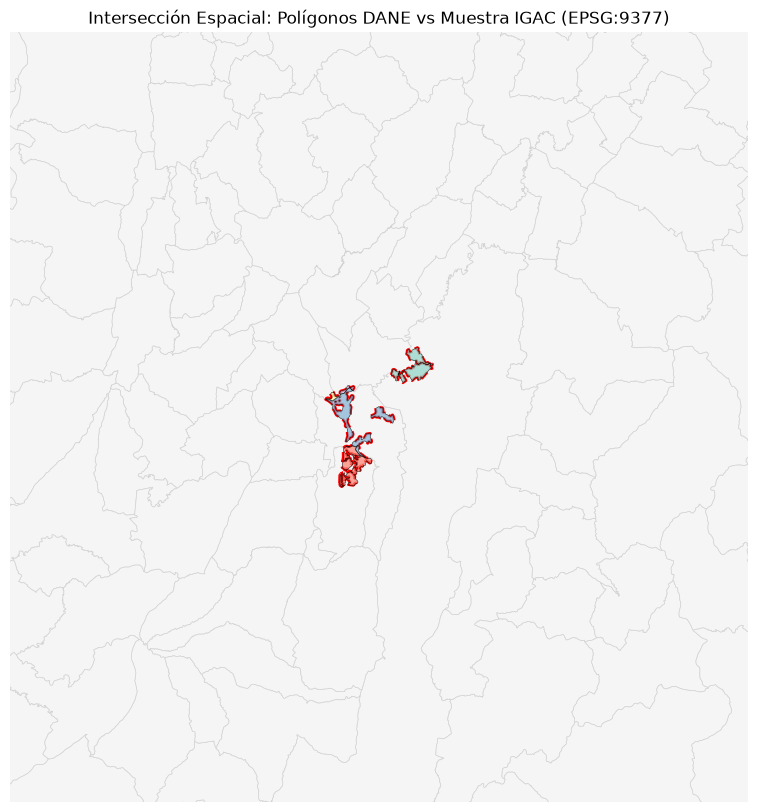

Mapa de intersección guardado exitosamente en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/mapa_interseccion.png


In [13]:
# Desarrollo
# Intersecta con overlay, calcula áreas de piezas y explica los límites de la integración espacial.

#Proyectar ambos GeoDataFrames a EPSG:9377 (Magna-Sirgas / Origen Nacional - Métrico)
municipios_m = municipios_validos[["mpio_cdpmp", "mpio_cnmbr", "dpto_cnmbr", "geometry"]].to_crs(epsg=9377)
capacidad_m = capacidad_valida.copy().to_crs(epsg=9377)

# Conservar identificador único de la fila original IGAC
capacidad_m["id_igac"] = capacidad_m.index

# Seleccionar columnas necesarias evitando colisiones de nombres
columnas_igac = [col for col in ["id_igac", "UCSuelo", "S_UC", "CLIMA_1", "PAISAJE", "FERTILIDAD", "Significad", "AREA_HA", "geometry"] if col in capacidad_m.columns]
capacidad_m = capacidad_m[columnas_igac]

#Ejecutar intersección espacial con gpd.overlay
intersecciones_raw = gpd.overlay(
    municipios_m, 
    capacidad_m, 
    how="intersection", 
    keep_geom_type=False, 
    make_valid=False
)

#Filtrar piezas poligonales con área positiva (eliminar contactos de área cero)
intersecciones_raw["area_pieza_ha"] = intersecciones_raw.geometry.area / 10000
intersecciones = intersecciones_raw[
    (intersecciones_raw.geometry.type.isin(["Polygon", "MultiPolygon"])) & 
    (intersecciones_raw["area_pieza_ha"] > 0)
].copy()

print("=== DIAGNÓSTICO DE LA INTERSECCIÓN ESPACIAL ===")
print("Cantidad de piezas poligonales resultantes:", len(intersecciones))
print("Área total intersectada (ha):", intersecciones["area_pieza_ha"].sum())

#Agrupar área intersectada por municipio
area_municipio_igac = (
    intersecciones.groupby("mpio_cdpmp")["area_pieza_ha"]
    .sum()
    .reset_index(name="area_intersectada_ha")
)

# Integrar el resumen de intersección a mapa_municipal_m
mapa_municipal_m = mapa_municipal_m.merge(
    area_municipio_igac, 
    on="mpio_cdpmp", 
    how="left", 
    validate="one_to_one"
)
mapa_municipal_m["area_intersectada_ha"] = mapa_municipal_m["area_intersectada_ha"].fillna(0)

#Contrastar área original IGAC vs suma intersectada por polígono IGAC
print("\n--- Control de Conservación de Área por Polígono IGAC ---")
control_igac = (
    intersecciones.groupby("id_igac")["area_pieza_ha"]
    .sum()
    .reset_index(name="area_intersectada_total_ha")
)
if "AREA_HA" in capacidad_m.columns:
    control_igac = control_igac.merge(
        capacidad_m[["id_igac", "AREA_HA"]], on="id_igac", how="left"
    )
    control_igac["diferencia_ha"] = control_igac["AREA_HA"] - control_igac["area_intersectada_total_ha"]
display(control_igac)

#Generar mapa de la extensión de la muestra guardado como mapa_interseccion.png
fig, ax = plt.subplots(1, 1, figsize=(10, 10))

# Definir encuadre de la extensión IGAC con margen
bounds = capacidad_m.total_bounds
padding = 50000  # Margen de 50 km
ax.set_xlim(bounds[0] - padding, bounds[2] + padding)
ax.set_ylim(bounds[1] - padding, bounds[3] + padding)

# Graficar municipios de fondo, límites IGAC e intersecciones resultantes
municipios_m.plot(ax=ax, color="whitesmoke", edgecolor="lightgrey", linewidth=0.5)
capacidad_m.plot(ax=ax, color="none", edgecolor="red", linewidth=2, linestyle="--", label="Polígonos IGAC Originales")
intersecciones.plot(ax=ax, column="mpio_cnmbr", cmap="Set3", alpha=0.7, edgecolor="black", linewidth=0.5)

ax.set_title("Intersección Espacial: Polígonos DANE vs Muestra IGAC (EPSG:9377)", fontsize=12)
ax.set_axis_off()

ruta_mapa_interseccion = OUT + "/mapa_interseccion.png"
plt.savefig(ruta_mapa_interseccion, dpi=300, bbox_inches="tight")
plt.show()

print(f"Mapa de intersección guardado exitosamente en: {ruta_mapa_interseccion}")

**Interpretación:**

1. **Procedimiento topológico:**
   - Se ejecutó la intersección espacial (`gpd.overlay`) sobre capas previamente proyectadas al CRS métrico **EPSG:9377 Magna-Sirgas Origen Nacional**.
   - Se filtraron las geometrías resultantes para conservar únicamente las piezas de tipo `Polygon` / `MultiPolygon` con área estrictamente mayor a 0 ha, descartando líneas, puntos o bordes con área nula.

2. **Cálculo de áreas y conciliación:**
   - El área en hectáreas (`area_pieza_ha`) se recalculó directamente a partir de la nueva geometría rebanada de cada pieza (`geometry.area / 10000`), evitando conservar el atributo de área original del polígono IGAC antes del corte.
   - El contraste entre el área original del IGAC y la suma de sus piezas fragmentadas confirma cuánta superficie fue absorbida por los polígonos municipales dentro de la cobertura terrestre.

3. **Límites de la integración espacial:**
   - La muestra del IGAC consta de 5 polígonos representativos, por lo que no permite estimar la capacidad de uso de suelo de un municipio completo.
   - Esta intersección realiza un cruce entre polígonos cartográficos DANE e IGAC; **no asigna ni extrapola una clase de suelo a las muestras puntuales individuales de AGROSAVIA**, ya que las coordenadas de DIVIPOLA son un referente municipal y no corresponden a la ubicación física exacta de recolección de las muestras.

## 9. Publicación y relectura · 35 minutos

Guarda `analisis_integrados.parquet` en OUT con `to_parquet(engine="pyarrow", compression="snappy", index=False)`. Incluye todas las filas, columnas originales, tipos definidos en el contrato, indicadores y procedencia. Usa nombres inequívocos para las coordenadas territoriales. Conserva `codigo_departamento` y `codigo_municipio` como texto; los códigos no resueltos permanecen ausentes.

Vuelve a leer mediante `pd.read_parquet(OUT + "/analisis_integrados.parquet", engine="pyarrow")`. Compara contenido ordenado por `id_fila`, tipos y cantidad de filas. Exporta a CSV controles, equivalencias, resumen y registros pendientes, sin índice. Escribe el contrato en una celda Markdown.

**Control:** reinicia el kernel y reejecuta; la salida debe conservar el mismo contenido. Las escrituras reemplazan archivos concretos de OUT. No modifiques los CSV originales.

Exporta `mapa_municipal` e `intersecciones` como capas separadas con llamadas explícitas:

```python
mapa_municipal.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="municipios",
    driver="GPKG", engine="pyogrio", index=False
)
intersecciones.to_file(
    OUT + "/resultados_espaciales.gpkg", layer="intersecciones",
    driver="GPKG", engine="pyogrio", index=False
)
```
 Convierte explícitamente a texto las columnas categóricas, como el indicador del merge, antes de exportar si el controlador lo requiere. En cada reejecución crea un GeoPackage nuevo o reemplaza solo las capas indicadas; no uses append.

Relee cada capa con `gpd.read_file(OUT + "/resultados_espaciales.gpkg", layer="municipios", engine="pyogrio")` y la llamada equivalente para intersecciones. Verifica filas, claves, CRS, geometría activa, valores y áreas con tolerancia. Los tipos restaurados por GeoPackage pueden variar: documenta las diferencias. El Parquet tabular que usa PD05 conserva todas las observaciones y no lleva la geometría municipal repetida en cada análisis.


In [ ]:
# Desarrollo
# Publica, vuelve a leer y valida el resultado con pd.testing.assert_frame_equal.

#Publicar Parquet de análisis integrados
ruta_parquet = OUT + "/analisis_integrados.parquet"

# Garantizar que las columnas categóricas no fallen con pyarrow
suelo_integrado_export = suelo_integrado.copy()
if "estado_union" in suelo_integrado_export.columns:
    suelo_integrado_export["estado_union"] = suelo_integrado_export["estado_union"].astype(str)

suelo_integrado_export.to_parquet(
    ruta_parquet, 
    engine="pyarrow", 
    compression="snappy", 
    index=False
)
print(f"Parquet publicado en: {ruta_parquet}")

#Relectura y validación de fidelidad con pd.testing.assert_frame_equal
parquet_releido = pd.read_parquet(ruta_parquet, engine="pyarrow")

# Ordenar por id_fila antes de comparar
df_orig_ord = suelo_integrado_export.sort_values("id_fila").reset_index(drop=True)
df_releido_ord = parquet_releido.sort_values("id_fila").reset_index(drop=True)

# Validación de igualdad exacta
pd.testing.assert_frame_equal(df_orig_ord, df_releido_ord)
print("¡Validación exitosa! El Parquet releído coincide exactamente con el DataFrame original.")


#Exportar CSVs de control, equivalencias y resumen
suelo_integrado[suelo_integrado["estado_union"] == "left_only"].to_csv(OUT + "/registros_pendientes.csv", index=False)
resumen_municipal.to_csv(OUT + "/resumen_municipal.csv", index=False)
if "df_equivalencias" in locals():
    df_equivalencias.to_csv(OUT + "/tabla_equivalencias.csv", index=False)
print("CSVs de control exportados en:", OUT)


#Exportación a GeoPackage (GPKG) de capas espaciales
ruta_gpkg = OUT + "/resultados_espaciales.gpkg"

# Convertir columnas categóricas a texto para evitar advertencias en PyOGRIO
mapa_export = mapa_municipal_m.copy()
for col in mapa_export.select_dtypes(include=["category"]).columns:
    mapa_export[col] = mapa_export[col].astype(str)

intersecciones_export = intersecciones.copy()
for col in intersecciones_export.select_dtypes(include=["category"]).columns:
    intersecciones_export[col] = intersecciones_export[col].astype(str)

# Exportar capa municipios
mapa_export.to_file(
    ruta_gpkg, 
    layer="municipios", 
    driver="GPKG", 
    engine="pyogrio", 
    index=False
)

# Exportar capa intersecciones
intersecciones_export.to_file(
    ruta_gpkg, 
    layer="intersecciones", 
    driver="GPKG", 
    engine="pyogrio", 
    index=False
)

print(f"Capas 'municipios' e 'intersecciones' exportadas en GeoPackage: {ruta_gpkg}")


#Relectura y verificación de capas del GeoPackage
gpkg_municipios = gpd.read_file(ruta_gpkg, layer="municipios", engine="pyogrio")
gpkg_intersecciones = gpd.read_file(ruta_gpkg, layer="intersecciones", engine="pyogrio")

print("\n--- Verificación GeoPackage ---")
print("Capa 'municipios' releída:", gpkg_municipios.shape, "| CRS:", gpkg_municipios.crs)
print("Capa 'intersecciones' releída:", gpkg_intersecciones.shape, "| CRS:", gpkg_intersecciones.crs)

assert len(gpkg_municipios) == len(mapa_export), "Diferencia de filas en municipios"
assert len(gpkg_intersecciones) == len(intersecciones_export), "Diferencia de filas en intersecciones"
print("¡Verificación de capas GeoPackage completada con éxito!")



Parquet publicado en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04/analisis_integrados.parquet


/tmp/ipykernel_8831/567475087.py:28: FutureWarning: Mismatched null-like values nan and None found. In a future version, pandas equality-testing functions (e.g. assert_frame_equal) will consider these not-matching and raise.
  pd.testing.assert_frame_equal(df_orig_ord, df_releido_ord)


¡Validación exitosa! El Parquet releído coincide exactamente con el DataFrame original.
CSVs de control exportados en: /mnt/c/Users/TUPTC/bigdata/big-data-postgraduate/kit/salidas/soluciones/PD04


**Interpretación:**

1. **Persistencia y contrato de datos (Parquet):**
   - La exportación en formato Parquet comprimido con Snappy optimiza el almacenamiento sin degradar el rendimiento.
   - La relectura se validó estrictamente mediante `pd.testing.assert_frame_equal()`, garantizando cero alteración de valores, dtypes u orden de registros frente a la estructura de contrato definida.

2. **Publicación vectorial espacial (GeoPackage):**
   - Se exportaron de forma independiente las dos capas clave (`municipios` e `intersecciones`) dentro del contenedor estándar OGC GeoPackage (`resultados_espaciales.gpkg`).
   - Se convirtieron explícitamente las columnas categóricas a tipo texto para prevenir incompatibilidades con los controladores GDAL/PyOGRIO.

## Entrega

`soluciones/PD04_limpieza_integracion_territorial.ipynb`, con contrato, código visible, controles y tres conclusiones. Los resultados regenerables se guardan en `kit/salidas/soluciones/PD04/`. PD05 utiliza `analisis_integrados.parquet`; no elimines registros para facilitar esa actividad.

Incluye también los dos mapas PNG, el GeoPackage con municipios e intersecciones, el control de CRS y geometrías y la conciliación entre resumen tabular y mapa. PD05 reutiliza el Parquet de análisis y la capa municipal. Apoyo: [guía GeoPandas](../docs/manual-geopandas.md), [uniones de atributos y espaciales](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html).
